In [26]:
import random
import math
import networkx as nx
import matplotlib.pyplot as plt

In [23]:
from values import list

In [24]:
random.shuffle(list)
print(list)

['Cleanliness', 'Excellence', 'Equality', 'Friendship', 'Competence', 'Wealth', 'Inner Harmony', 'Playfulness', 'Patriotism', 'Teamwork', 'Responsibility', 'Joy', 'Control', 'Calmness', 'Ethical', 'Prosperity', 'Courage', 'Adventure', 'Skillfulness', 'Leadership', 'Efficiency', 'Fame', 'Organization', 'Intelligence', 'Goodness', 'Gratitude', 'Success', 'Forgiveness', 'Diversity', 'Contribution', 'Boldness', 'Insightful', 'Accuracy', 'Family', 'Rigor', 'Fidelity', 'Careful', 'Compassion', 'Thoughtful', 'Selfless', 'Health', 'Growth', 'Authenticity', 'Thankful', 'Affection', 'Awareness', 'Loyalty', 'Inspiring', 'Positivity', 'Empathy', 'Maturity', 'Purpose', 'Toughness', 'Peace', 'Balance', 'Capable', 'Status', 'Determination', 'Contentment', 'Happiness', 'Certainty', 'Hard Work', 'Sincerity', 'Beauty', 'Devotion', 'Self-development', 'Lawful', 'Communication', 'Sustainability', 'Poise', 'Acceptance', 'Consistency', 'Support', 'Stewardship', 'Temperance', 'Accomplishment', 'Respect', 'St

In [6]:
def next_power_of_two(n):
    return 1 if n == 0 else 2 ** math.ceil(math.log2(n))


def pad_teams_with_byes(teams):
    target_size = next_power_of_two(len(teams))
    byes_needed = target_size - len(teams)
    return teams + ["BYE"] * byes_needed

In [ ]:
def run_tournament(teams):
    teams = pad_teams_with_byes(teams)

    rounds = []
    current_round = teams[:]
    round_num = 1

    while len(current_round) > 1:
        print(f"\n--- Round {round_num} ---")
        next_round = []
        matchups = []

        for i in range(0, len(current_round), 2):
            team1 = current_round[i]
            team2 = current_round[i + 1]

            # Handle BYEs automatically
            if team1 == "BYE":
                winner = team2
                print(f"{team2} advances (BYE)")
            elif team2 == "BYE":
                winner = team1
                print(f"{team1} advances (BYE)")
            else:
                print(f"\nMatch: 1) {team1} vs 2) {team2}")
                choice = input("Pick winner (1 or 2): ")

                while choice not in ["1", "2"]:
                    choice = input("Invalid. Pick 1 or 2: ")

                winner = team1 if choice == "1" else team2

            next_round.append(winner)
            matchups.append((team1, team2, winner))

        rounds.append(matchups)
        current_round = next_round
        round_num += 1

    print(f"\n🏆 Champion: {current_round[0]}")
    return rounds

In [40]:
def plot_bracket(rounds):
    G = nx.DiGraph()
    pos = {}
    labels = {}

    x_spacing = 3
    y_spacing = 1.5

    for r, round_matches in enumerate(rounds):
        for m, (t1, t2, winner) in enumerate(round_matches):
            y = -m * (2 ** r)

            # Add nodes
            for team in [t1, t2, winner]:
                if team != "BYE":
                    G.add_node(team)
                    labels[team] = team

            # Add edges (skip BYEs)
            if (t1 != "BYE") & (t1 != winner):
                G.add_edge(t1, winner)
            if (t2 != "BYE") & (t2 != winner):
                G.add_edge(t2, winner)

            # Positioning
            if t1 != "BYE":
                pos[t1] = (r * x_spacing, y + y_spacing)
            if t2 != "BYE":
                pos[t2] = (r * x_spacing, y - y_spacing)

            if winner != "BYE":
                pos[winner] = ((r + 1) * x_spacing, y)

    plt.figure(figsize=(14, 14))
    nx.draw(G, pos, with_labels=True, labels=labels,
            node_size=2000, node_color="lightgreen", font_size=8)
    plt.title("Tournament Bracket (with BYEs)")
    plt.show()

In [27]:
rounds = run_tournament(list)


--- Round 1 ---

Match: 1) Attentive vs 2) Compassion

Match: 1) Order vs 2) Prosperity

Match: 1) Acceptance vs 2) Giving

Match: 1) Uniqueness vs 2) Recognition

Match: 1) Determination vs 2) Openness

Match: 1) Intuitive vs 2) Charity

Match: 1) Structure vs 2) Comfort

Match: 1) Brilliance vs 2) Patience

Match: 1) Joy vs 2) Humor

Match: 1) Grace vs 2) Calmness

Match: 1) Traditional vs 2) Friendship

Match: 1) Security vs 2) Originality

Match: 1) Equality vs 2) Decisiveness

Match: 1) Careful vs 2) Excellence

Match: 1) Clever vs 2) Dedication

Match: 1) Affection vs 2) Sustainability

Match: 1) Devotion vs 2) Vitality

Match: 1) Enthusiasm vs 2) Leadership

Match: 1) Fame vs 2) Goodness

Match: 1) Moderation vs 2) Credibility

Match: 1) Responsibility vs 2) Courage

Match: 1) Energy vs 2) Speed

Match: 1) Awareness vs 2) Thankful

Match: 1) Purpose vs 2) Organization

Match: 1) Forgiveness vs 2) Wealth

Match: 1) Understanding vs 2) Humility

Match: 1) Bravery vs 2) Learning



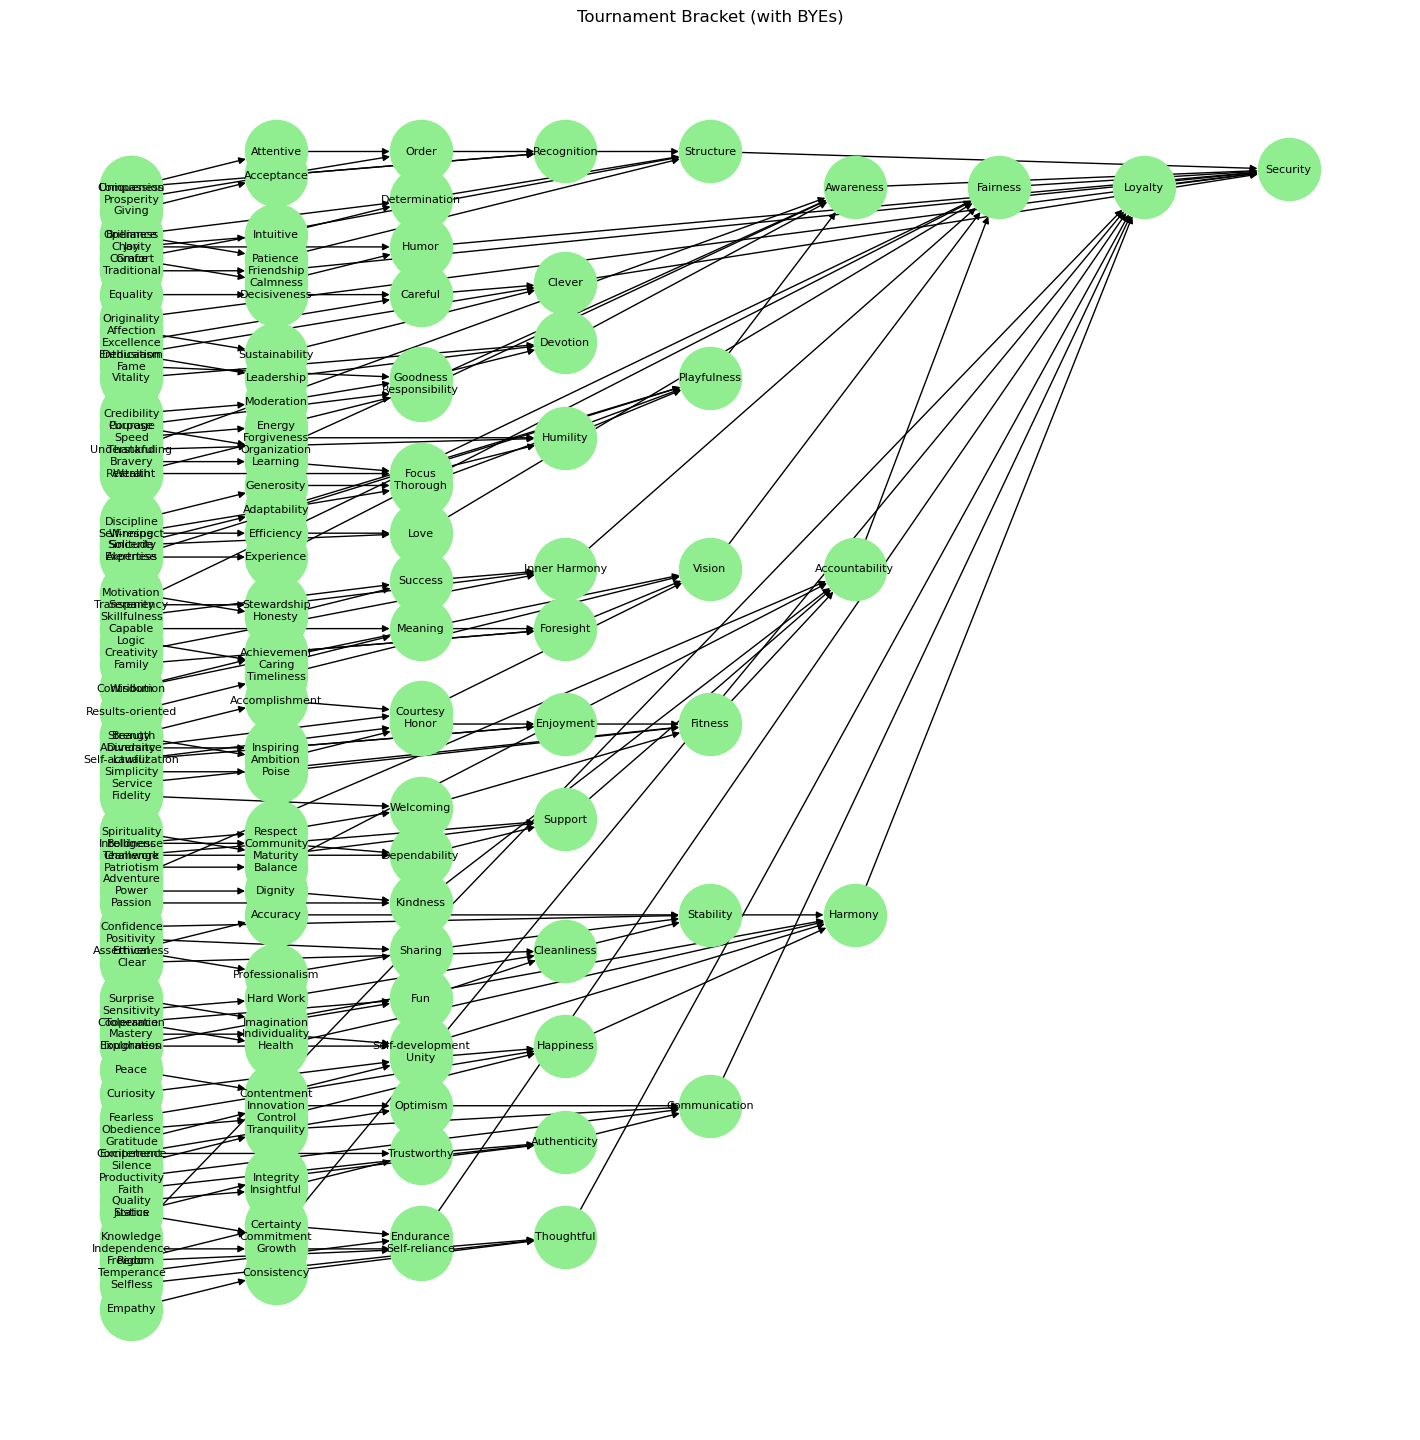

In [41]:
plot_bracket(rounds)

In [35]:
rounds

[[('Attentive', 'Compassion', 'Attentive'),
  ('Order', 'Prosperity', 'Order'),
  ('Acceptance', 'Giving', 'Acceptance'),
  ('Uniqueness', 'Recognition', 'Recognition'),
  ('Determination', 'Openness', 'Determination'),
  ('Intuitive', 'Charity', 'Intuitive'),
  ('Structure', 'Comfort', 'Structure'),
  ('Brilliance', 'Patience', 'Patience'),
  ('Joy', 'Humor', 'Humor'),
  ('Grace', 'Calmness', 'Calmness'),
  ('Traditional', 'Friendship', 'Friendship'),
  ('Security', 'Originality', 'Security'),
  ('Equality', 'Decisiveness', 'Decisiveness'),
  ('Careful', 'Excellence', 'Careful'),
  ('Clever', 'Dedication', 'Clever'),
  ('Affection', 'Sustainability', 'Sustainability'),
  ('Devotion', 'Vitality', 'Devotion'),
  ('Enthusiasm', 'Leadership', 'Leadership'),
  ('Fame', 'Goodness', 'Goodness'),
  ('Moderation', 'Credibility', 'Moderation'),
  ('Responsibility', 'Courage', 'Responsibility'),
  ('Energy', 'Speed', 'Energy'),
  ('Awareness', 'Thankful', 'Awareness'),
  ('Purpose', 'Organizatio